MNIST veri kümesi yükleniyor...
Tüm veri küması için toplam 30 prototip aranıyor (K-Means)...

--- Rakam Başına Düşen Prototip Sayıları ---
Rakam '0': 5 adet prototipe sahip
Rakam '1': 3 adet prototipe sahip
Rakam '2': 3 adet prototipe sahip
Rakam '3': 4 adet prototipe sahip
Rakam '4': 3 adet prototipe sahip
Rakam '5': 2 adet prototipe sahip
Rakam '6': 3 adet prototipe sahip
Rakam '7': 3 adet prototipe sahip
Rakam '8': 2 adet prototipe sahip
Rakam '9': 2 adet prototipe sahip


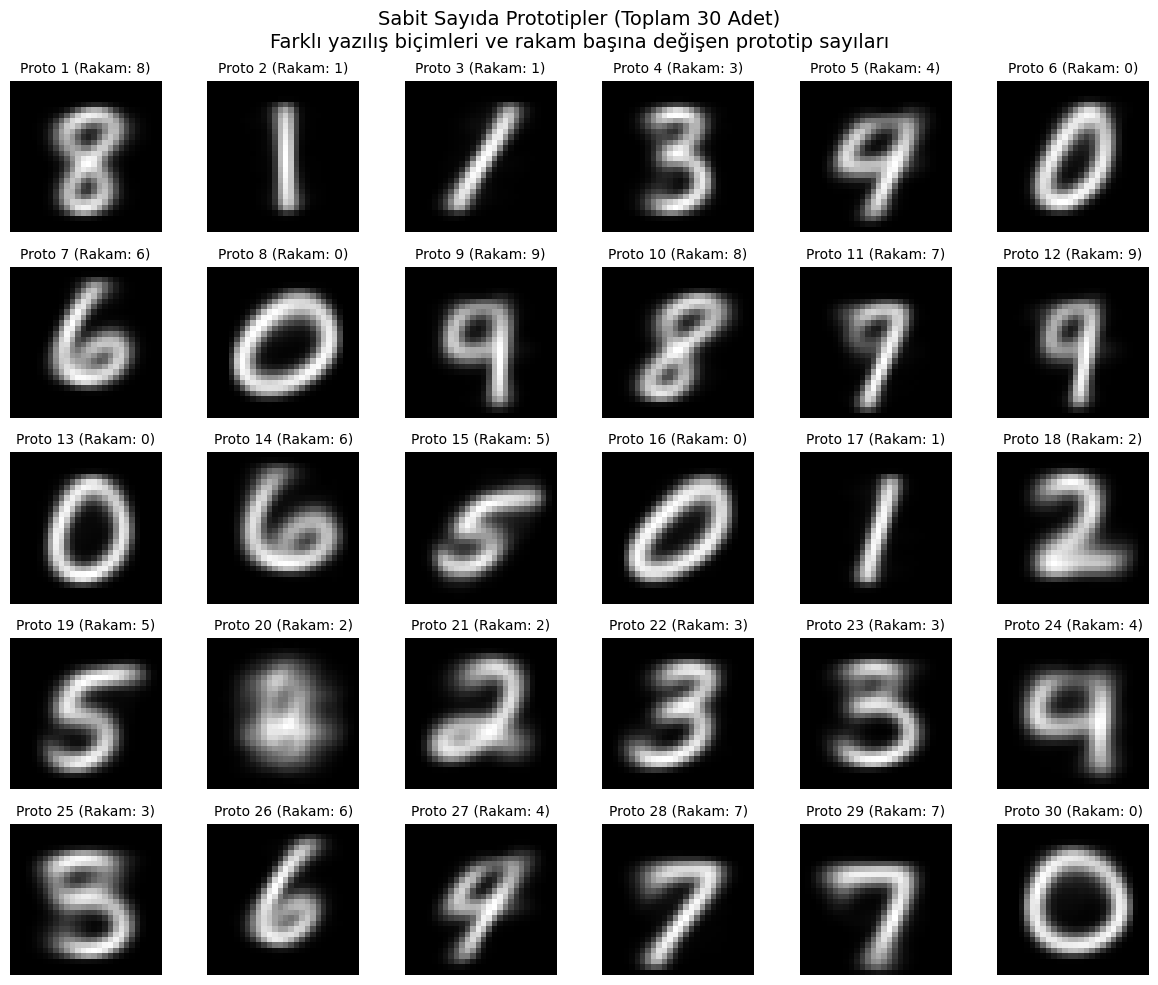

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.cluster import KMeans
from sklearn.datasets import fetch_openml

# 1. MNIST el yazısı veri kümesini yükle (Rakamlar 0-9)
print("MNIST veri kümesi yükleniyor...")
X, y = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False)
y = y.astype(int)

# Veriyi ölçeklendir (0-1 arasına getir)
X = X / 255.0

# 2. TÜM VERİ KÜMESİ İÇİN SABİT SAYIDA PROTOTİP BELİRLE
# Sınıf başına değil, tüm küme için toplam 30 prototip (küme merkezi) arıyoruz.
TOTAL_PROTOTYPES = 30

print(
    f"Tüm veri küması için toplam {TOTAL_PROTOTYPES} prototip aranıyor (K-Means)..."
)
kmeans = KMeans(n_clusters=TOTAL_PROTOTYPES, random_state=42, n_init=10)
kmeans.fit(X)

# Prototipler (küme merkezleri) ve her prototipin en yakın olduğu gerçek etiketi bulma
prototypes = kmeans.cluster_centers_  # (30, 784) boyutunda prototipler
cluster_labels = kmeans.labels_

# Her bir prototipe en çok temsil ettiği sınıfı (rakamı) atayalım
prototype_class_assignment = []
for i in range(TOTAL_PROTOTYPES):
    # i. kümeye düşen gerçek veri noktalarının etiketleri
    labels_in_cluster = y[cluster_labels == i]
    if len(labels_in_cluster) > 0:
        # En çok tekrar eden rakamı bu prototipin sınıfı kabul et
        most_frequent_label = np.bincount(labels_in_cluster).argmax()
        prototype_class_assignment.append(most_frequent_label)
    else:
        prototype_class_assignment.append(-1)

prototype_class_assignment = np.array(prototype_class_assignment)

# 3. RAKAM BAŞINA DÜŞEN PROTOTİP SAYISINI İNCELEME
print("\n--- Rakam Başına Düşen Prototip Sayıları ---")
unique_digits, counts = np.unique(prototype_class_assignment, return_counts=True)
for digit, count in zip(unique_digits, counts):
    print(f"Rakam '{digit}': {count} adet prototipe sahip")

# 4. PROTOTİPLERİ VE DEĞİŞİK YAZILIŞ BİÇİMLERİNİ GÖRSELLEŞTİRME
rows = 5
cols = 6
fig, axes = plt.subplots(rows, cols, figsize=(12, 10))
fig.suptitle(
    f"Sabit Sayıda Prototipler (Toplam {TOTAL_PROTOTYPES} Adet)\n"
    "Farklı yazılış biçimleri ve rakam başına değişen prototip sayıları",
    fontsize=14,
)

for i, ax in enumerate(axes.flat):
    if i < TOTAL_PROTOTYPES:
        # 784 boyutlu prototipi 28x28 görüntüye geri çevir
        proto_img = prototypes[i].reshape(28, 28)
        assigned_digit = prototype_class_assignment[i]

        ax.imshow(proto_img, cmap="gray")
        ax.set_title(f"Proto {i+1} (Rakam: {assigned_digit})", fontsize=10)
        ax.axis("off")
    else:
        ax.axis("off")

plt.tight_layout()
plt.show()